In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load the credit card transaction dataset
df = pd.read_csv("creditcard.csv")

print("DATASET LOADED SUCCESSFULLY")
print("-" * 40)
print("Dataset shape:", df.shape)

print("\nFirst five transactions:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# Analyze fraud class distribution
class_counts = df["Class"].value_counts().sort_index()
fraud_percentage = df["Class"].mean() * 100

print("\nTransaction class counts:")
display(class_counts.rename(index={
    0: "Legitimate",
    1: "Fraudulent"
}).to_frame("Number of Transactions"))

print(f"\nFraudulent transactions: {fraud_percentage:.4f}%")
print(f"Legitimate transactions: {100 - fraud_percentage:.4f}%")


DATASET LOADED SUCCESSFULLY
----------------------------------------
Dataset shape: (284807, 31)

First five transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0



Transaction class counts:


,Number of Transactions
Class,
Legitimate,284315
Fraudulent,492



Fraudulent transactions: 0.1727%
Legitimate transactions: 99.8273%



## 1. Dataset Overview

This project uses the Credit Card Fraud Detection dataset from Kaggle. Each row represents a financial transaction. The target column, `Class`, identifies legitimate transactions as 0 and fraudulent transactions as 1.

The dataset contains anonymized numerical features V1 through V28, along with transaction time and amount. The goal is to identify fraudulent transactions while minimizing missed fraud cases.

A major challenge is class imbalance: fraudulent transactions represent only a very small fraction of all transactions. Therefore, evaluation must consider precision, recall, F1-score, and ROC-AUC instead of relying on accuracy alone.


CLASS IMBALANCE SUMMARY
----------------------------------------
Legitimate transactions: 284,315 (99.8273%)
Fraudulent transactions: 492 (0.1727%)


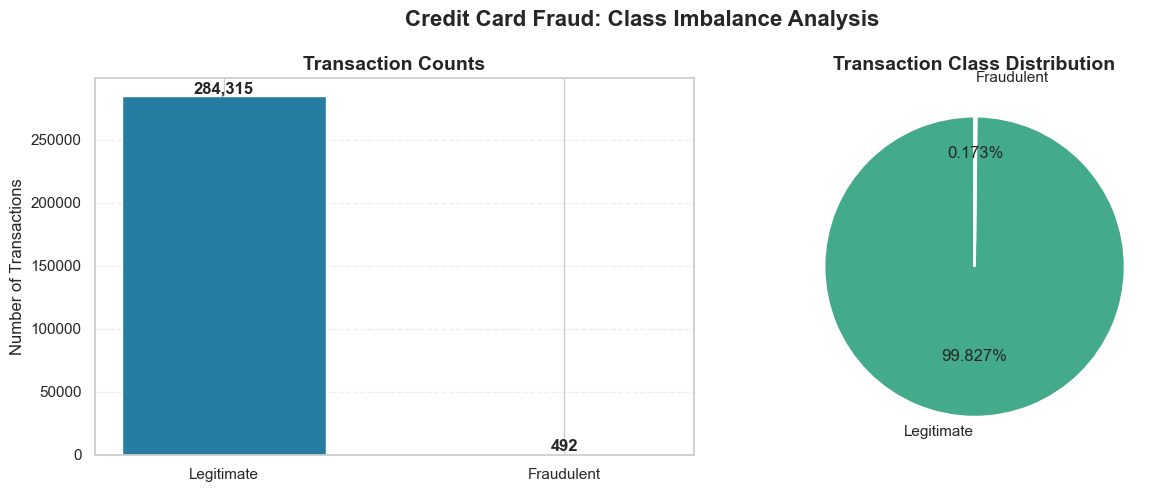

In [2]:
# Visualizing Class Imbalance

class_counts = df["Class"].value_counts().sort_index()

legitimate_count = int(class_counts[0])
fraud_count = int(class_counts[1])

legitimate_percentage = legitimate_count / len(df) * 100
fraud_percentage = fraud_count / len(df) * 100

print("CLASS IMBALANCE SUMMARY")
print("-" * 40)
print(f"Legitimate transactions: {legitimate_count:,} ({legitimate_percentage:.4f}%)")
print(f"Fraudulent transactions: {fraud_count:,} ({fraud_percentage:.4f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Transaction counts
bars = axes[0].bar(
    ["Legitimate", "Fraudulent"],
    [legitimate_count, fraud_count],
    color=["#277DA1", "#F94144"],
    edgecolor="white",
    width=0.6
)

axes[0].set_title("Transaction Counts", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Number of Transactions")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

for bar in bars:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# Percentage distribution
axes[1].pie(
    [legitimate_count, fraud_count],
    labels=["Legitimate", "Fraudulent"],
    colors=["#43AA8B", "#F3722C"],
    autopct=lambda p: f"{p:.3f}%",
    startangle=90,
    explode=(0, 0.15),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

axes[1].set_title("Transaction Class Distribution", fontsize=14, fontweight="bold")

fig.suptitle(
    "Credit Card Fraud: Class Imbalance Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


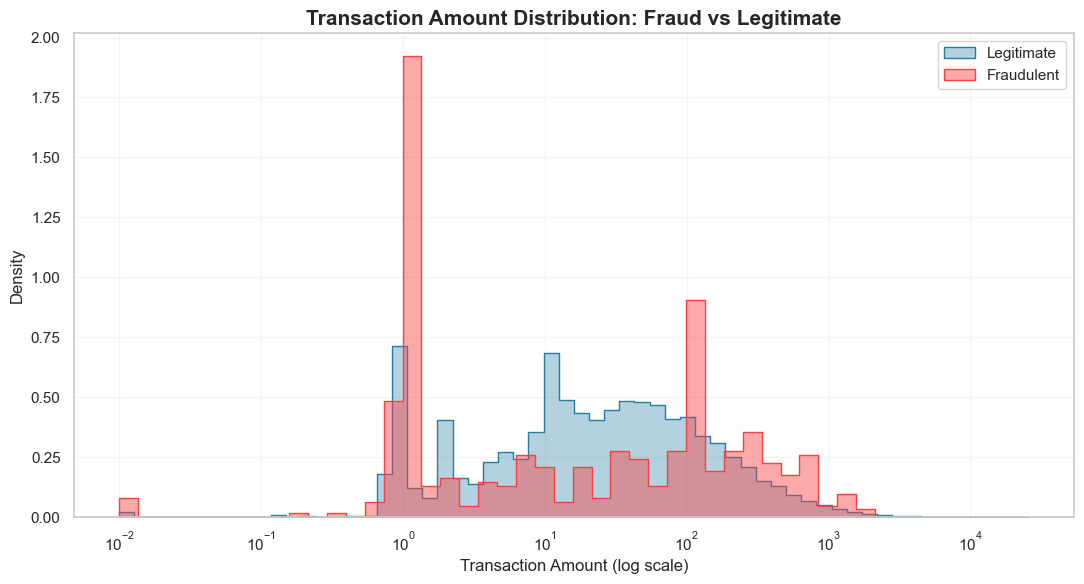

Transaction Amount Statistics


,count,mean,median,max
Class,,,,
Legitimate,284315,88.29,22.00,25691.16
Fraudulent,492,122.21,9.25,2125.87


In [3]:
# Transaction Amount Analysis

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=60,
    stat="density",
    element="step",
    fill=True,
    color="#277DA1",
    alpha=0.35,
    label="Legitimate",
    log_scale=(True, False)
)

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=40,
    stat="density",
    element="step",
    fill=True,
    color="#F94144",
    alpha=0.45,
    label="Fraudulent",
    log_scale=(True, False)
)

plt.title(
    "Transaction Amount Distribution: Fraud vs Legitimate",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Transaction Amount (log scale)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Compare transaction amount statistics
print("Transaction Amount Statistics")
display(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "max"])
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .round(2)
)


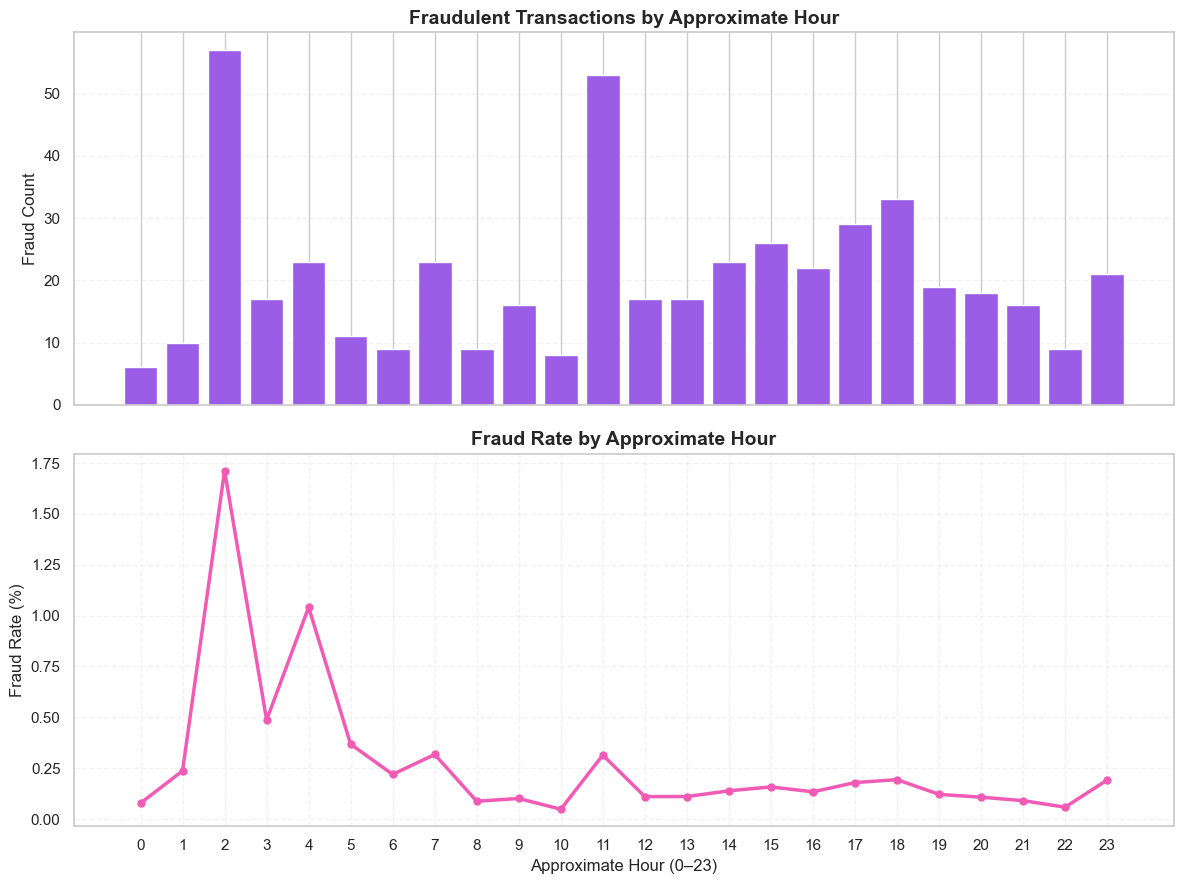

Hourly fraud analysis:


,Fraud_Count,Total_Transactions,Fraud_Rate_Percent
Hour,,,
0,6,7695,0.078
1,10,4220,0.237
2,57,3328,1.713
3,17,3492,0.487
4,23,2209,1.041
5,11,2990,0.368
6,9,4101,0.219
7,23,7243,0.318
8,9,10276,0.088


In [4]:
time_df = df.copy()

# Convert elapsed seconds into an approximate hour of day
time_df["Hour"] = ((time_df["Time"] // 3600) % 24).astype(int)

hourly_fraud = (
    time_df.groupby("Hour")["Class"]
    .agg(Fraud_Count="sum", Total_Transactions="count")
)

hourly_fraud["Fraud_Rate_Percent"] = (
    hourly_fraud["Fraud_Count"] /
    hourly_fraud["Total_Transactions"] * 100
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Chart 1: Number of fraudulent transactions per approximate hour
axes[0].bar(
    hourly_fraud.index,
    hourly_fraud["Fraud_Count"],
    color="#9B5DE5",
    edgecolor="white"
)
axes[0].set_title(
    "Fraudulent Transactions by Approximate Hour",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Fraud Count")
axes[0].grid(axis="y", linestyle="--", alpha=0.25)

# Chart 2: Fraud rate per approximate hour
axes[1].plot(
    hourly_fraud.index,
    hourly_fraud["Fraud_Rate_Percent"],
    color="#F15BB5",
    marker="o",
    linewidth=2.5,
    markersize=5
)
axes[1].set_title(
    "Fraud Rate by Approximate Hour",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Approximate Hour (0–23)")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_xticks(range(24))
axes[1].grid(linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()

print("Hourly fraud analysis:")
display(hourly_fraud.round(3))



## Exploratory Data Analysis: Amount and Time

Transaction amounts are compared between legitimate and fraudulent transactions. The logarithmic horizontal axis helps visualize amounts across a wide range of values. Summary statistics provide additional context, but amount alone may not reliably identify fraud.

The `Time` feature represents elapsed seconds from the first transaction rather than a real-world timestamp. Therefore, converting it into hours produces only an approximate 24-hour cycle and does not establish the actual local time of transactions.

Hourly fraud counts and fraud rates are both examined because counts can be affected by the number of transactions in each hour. These patterns are exploratory and should not be interpreted as proof of when fraud is most likely to occur.


##  Preparing Data for Machine Learning

The dataset is highly imbalanced, with very few fraudulent transactions compared to legitimate transactions. We will use a stratified train-test split to preserve the same proportion of fraud and legitimate transactions in both sets.

- **Training set:** Used to train the machine learning models.
- **Testing set:** Used to evaluate how well the models perform on unseen transactions.
- **Stratification:** Ensures that both sets contain a similar proportion of fraudulent transactions.

In [7]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Split data while preserving the fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATA SPLIT COMPLETED")
print("-" * 40)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in testing set:", int(y_test.sum()))

print("\nFraud percentage in training set:",
      round(y_train.mean() * 100, 4), "%")
print("Fraud percentage in testing set:",
      round(y_test.mean() * 100, 4), "%")


DATA SPLIT COMPLETED
----------------------------------------
Training samples: 227845
Testing samples: 56962

Fraud cases in training set: 394
Fraud cases in testing set: 98

Fraud percentage in training set: 0.1729 %
Fraud percentage in testing set: 0.172 %


In [10]:

%pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from imblearn.over_sampling import SMOTE

# Display class counts before SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

# Apply SMOTE only to training data
smote = SMOTE(sampling_strategy=0.2, random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train, y_train
)

# Display class counts after SMOTE
print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

print("\nOriginal training data shape:", X_train.shape)
print("Resampled training data shape:", X_train_resampled.shape)


Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1     45490
Name: count, dtype: int64

Original training data shape: (227845, 30)
Resampled training data shape: (272941, 30)


## Model 1: Logistic Regression

Logistic Regression is a classification algorithm used to predict whether a transaction is fraudulent or legitimate. We will use feature scaling and class weighting to improve learning from the imbalanced dataset.

The model will be trained using the resampled training data, while the original test data will remain unchanged.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Create Logistic Regression pipeline
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Train using the SMOTE-resampled training data
print("Training Logistic Regression model...")

logistic_model.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression model trained successfully!")


Training Logistic Regression model...
Logistic Regression model trained successfully!


## Model 2: Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions. It can capture complex relationships in transaction data and help identify fraudulent activity.

We will train the model on the SMOTE-resampled training data and use class weighting to help address class imbalance.

In [14]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest model...")

random_forest_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest model trained successfully!")


Training Random Forest model...
Random Forest model trained successfully!


## Model Evaluation

Accuracy alone is not sufficient for fraud detection because legitimate transactions greatly outnumber fraudulent ones.

We will evaluate our models using:

- **Precision:** How many transactions predicted as fraud were actually fraudulent?
- **Recall:** How many actual fraudulent transactions were detected?
- **F1-score:** The balance between precision and recall.
- **ROC-AUC:** How well the model separates fraudulent and legitimate transactions across different classification thresholds.

We will evaluate both models on the original, imbalanced test set, which better reflects real-world transaction data.

In [16]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    accuracy_score
)
import pandas as pd

# Store the models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():
    # Predict classes and fraud probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

print("MODEL EVALUATION RESULTS")
display(results_df.round(4))


MODEL EVALUATION RESULTS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9897,0.1327,0.8980,0.2313,0.9763
Random Forest,0.9995,0.8542,0.8367,0.8454,0.9600


## Comparing Model Performance

Visualizing model performance makes it easier to compare the strengths and weaknesses of Logistic Regression and Random Forest.

We will compare Precision, Recall, F1-score, and ROC-AUC. In fraud detection, recall is especially important because missing a fraudulent transaction can result in financial loss.

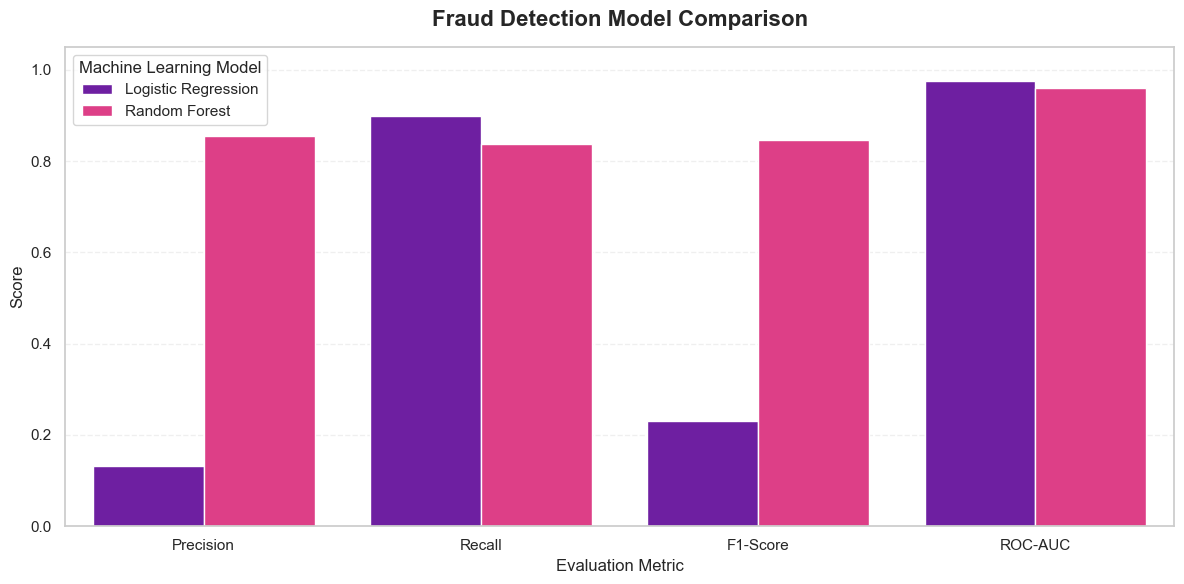

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the metrics for visualization
metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC"]

# Prepare chart
plot_data = results_df[metrics_to_plot].reset_index().melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    palette=["#7209B7", "#F72585"]
)

plt.title(
    "Fraud Detection Model Comparison",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title="Machine Learning Model")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## Confusion Matrix Analysis

A confusion matrix compares actual transaction classes with the classes predicted by a model.

- **True Negative (TN):** Legitimate transactions correctly identified.
- **False Positive (FP):** Legitimate transactions incorrectly flagged as fraud.
- **False Negative (FN):** Fraudulent transactions missed by the model.
- **True Positive (TP):** Fraudulent transactions correctly detected.

False negatives are particularly important in fraud detection because they represent fraudulent transactions that pass undetected.

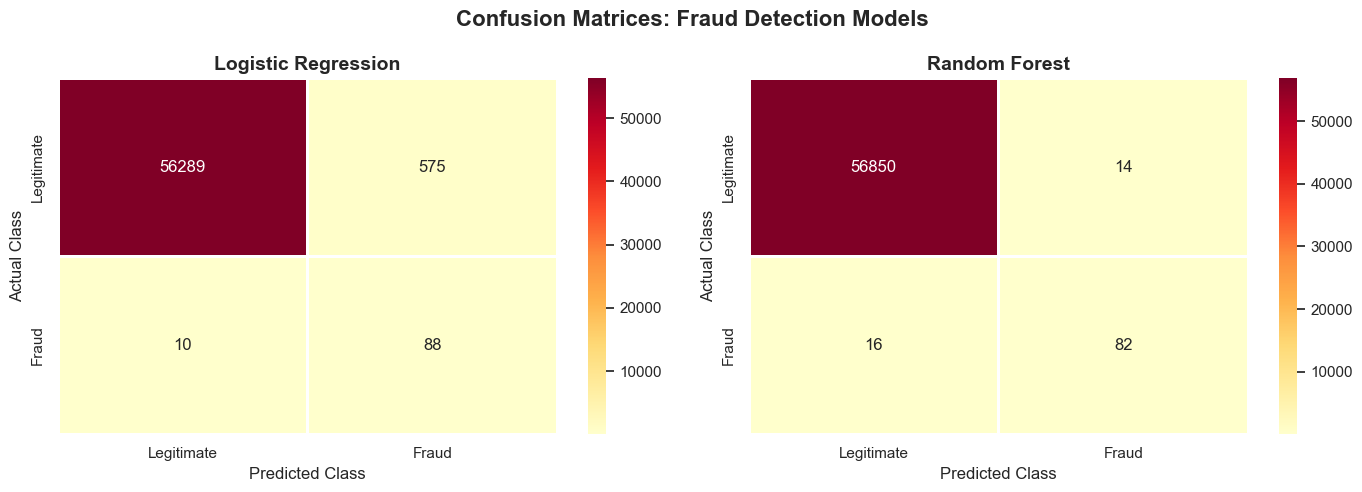

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlOrRd",
        linewidths=1,
        linecolor="white",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(model_name, fontsize=14, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrices: Fraud Detection Models",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


## ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve evaluates a classification model at different decision thresholds.

- **True Positive Rate:** The proportion of fraudulent transactions correctly detected.
- **False Positive Rate:** The proportion of legitimate transactions incorrectly flagged as fraud.
- **ROC-AUC:** A score closer to 1 generally indicates better discrimination between the two classes.

ROC-AUC should be considered alongside precision and recall, especially when the dataset is highly imbalanced.

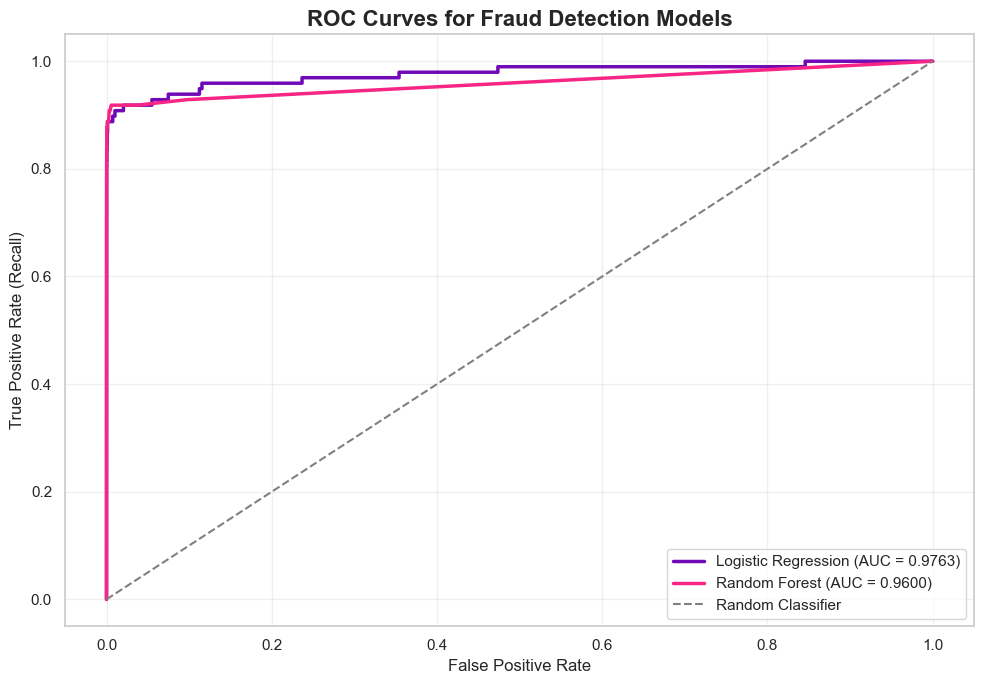

In [19]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

colors = ["#7209B7", "#F72585"]

for (model_name, model), color in zip(models.items(), colors):
    # Get predicted fraud probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2.5,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random Classifier"
)

plt.title("ROC Curves for Fraud Detection Models",
          fontsize=16, fontweight="bold")
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Feature Importance Analysis

Feature importance helps identify which transaction attributes contribute most to the Random Forest model's predictions.

The dataset contains anonymized PCA-transformed features (`V1` to `V28`), along with `Time` and `Amount`. Therefore, the original real-world meaning of most PCA features is not available.

We will visualize the ten most important features identified by the Random Forest model.

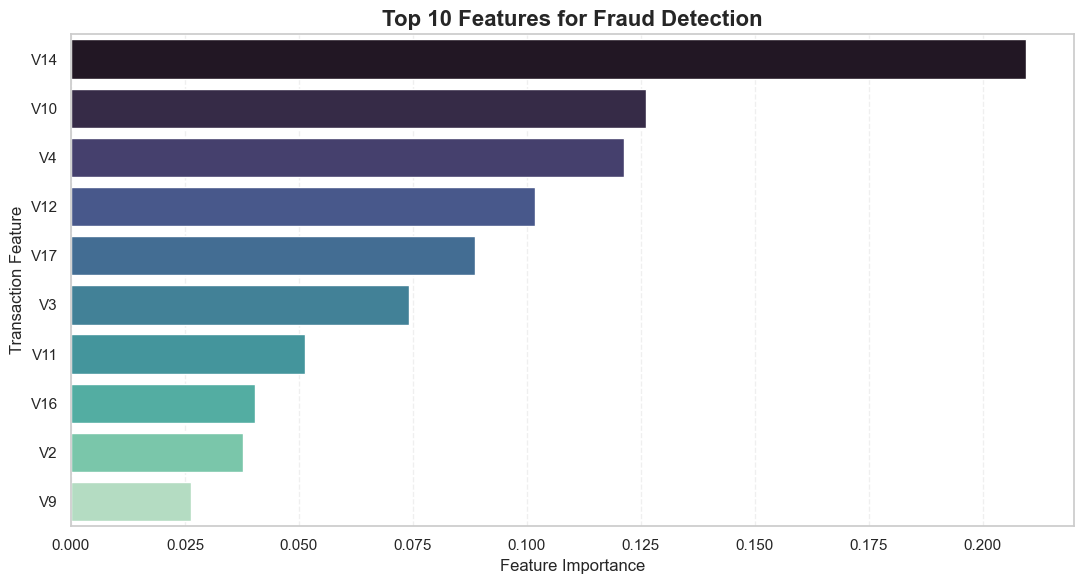

Top 10 Important Features:


,Feature,Importance
0,V14,0.20959
1,V10,0.12617
2,V4,0.12137
3,V12,0.10184
4,V17,0.08871
5,V3,0.07419
6,V11,0.05133
7,V16,0.04029
8,V2,0.03774
9,V9,0.02629


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract Random Forest feature importance
importance_df = pd.DataFrame({
    "Feature": X_train_resampled.columns,
    "Importance": random_forest_model.feature_importances_
})

# Select the top 10 features
top_features = importance_df.sort_values(
    by="Importance", ascending=False
).head(10)

# Plot feature importance
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="mako",
    legend=False
)

plt.title(
    "Top 10 Features for Fraud Detection",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Feature Importance")
plt.ylabel("Transaction Feature")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 Important Features:")
display(top_features.reset_index(drop=True).round(5))


## Precision–Recall Trade-off

In fraud detection, precision and recall must be balanced.

- **High recall:** Detects more fraudulent transactions, reducing missed fraud, but may generate more false alarms.
- **High precision:** Reduces false alarms, but may miss some fraudulent transactions.
- **Decision threshold:** Lowering the threshold usually catches more fraud but can increase false positives.

For financial fraud detection, recall is often prioritized when missing fraud is costly. However, the final threshold should also consider investigation costs and the inconvenience caused to legitimate customers.

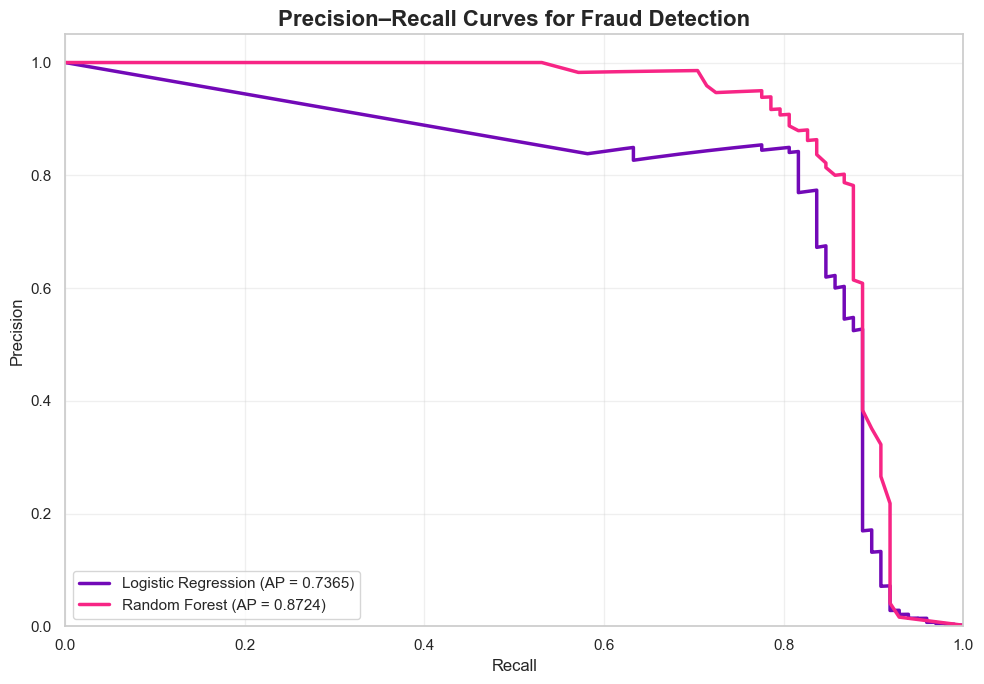

In [21]:

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

colors = ["#7209B7", "#F72585"]

for (model_name, model), color in zip(models.items(), colors):
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_prob
    )

    avg_precision = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        color=color,
        linewidth=2.5,
        label=f"{model_name} (AP = {avg_precision:.4f})"
    )

plt.title(
    "Precision–Recall Curves for Fraud Detection",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Scalability: Processing 1 Million Transactions per Hour

A real-world fraud detection system may need to process one million transactions per hour, which is approximately 278 transactions per second.

Our current notebook demonstrates fraud detection on a benchmark dataset. To deploy it at this scale, the system would need an efficient and reliable production architecture.

### Key scalability strategies

1. **Real-time data streaming:** Use Apache Kafka to receive transaction events continuously and distribute them across processing services.

2. **Fast model inference:** Deploy the trained model through a lightweight API using FastAPI. Benchmark prediction latency and throughput under realistic workloads.

3. **Distributed processing:** Use technologies such as Apache Flink or Spark when transaction volume and feature processing require distributed computation.

4. **Feature engineering:** Calculate transaction features efficiently and reuse precomputed information where possible. Avoid repeatedly performing expensive transformations for each transaction.

5. **Monitoring and retraining:** Monitor fraud recall, precision, false-positive rates, data drift, and model latency. Retrain or recalibrate the model when performance deteriorates.

6. **Reliable transaction handling:** Use timeouts, retries, idempotency, and fallback procedures so system failures do not cause duplicate processing or unnecessary transaction delays.

### Throughput calculation

- Transactions per hour: 1,000,000
- Average transactions per second: 1,000,000 ÷ 3,600 ≈ 278
- Production capacity: Must be benchmarked above the expected average to handle traffic spikes.

**Conclusion:** Processing one million transactions per hour is achievable with an appropriately designed system, but actual capacity depends on model complexity, hardware, feature-generation cost, latency requirements, and traffic patterns. This notebook has not yet benchmarked production throughput.

## Final Conclusion

This project developed a machine learning approach for detecting fraudulent credit card transactions using Python and scikit-learn.

### Work completed

- Loaded and explored the credit card transaction dataset.
- Analyzed the severe imbalance between legitimate and fraudulent transactions.
- Visualized transaction amounts and approximate transaction times.
- Used stratified train-test splitting to preserve the class distribution.
- Applied SMOTE to the training data to increase representation of fraudulent transactions.
- Trained Logistic Regression and Random Forest classifiers.
- Evaluated model performance using precision, recall, F1-score, ROC-AUC, confusion matrices, and ROC and precision–recall curves.
- Analyzed Random Forest feature importance.
- Discussed the trade-off between detecting more fraud and generating false alarms.
- Proposed strategies for scaling the system to process one million transactions per hour.

### Key findings

The evaluation results show how Logistic Regression and Random Forest differ in their ability to detect fraudulent transactions. The best model should be selected based on the evaluation metrics and the operational cost of missed fraud versus false alarms.

Accuracy alone is not a reliable measure for this highly imbalanced problem. Recall, precision, F1-score, ROC-AUC, and the confusion matrix provide a more complete view of performance.

### Future improvements

- Tune model hyperparameters and classification thresholds.
- Evaluate additional algorithms, such as XGBoost.
- Test on newer transaction data to assess generalization.
- Benchmark prediction speed and throughput.
- Monitor model drift and retrain when necessary.

### Overall conclusion

This project demonstrates how machine learning can help identify suspicious financial transactions. A real-world fraud detection system must combine strong model performance with low latency, reliable monitoring, and careful management of false positives and missed fraud.

In [22]:
print("FINAL FRAUD DETECTION MODEL SUMMARY")
print("=" * 45)

display(results_df.round(4))

print("\nBest model for each metric:")

for metric in ["Precision", "Recall", "F1-Score", "ROC-AUC"]:
    best_model = results_df[metric].idxmax()
    best_score = results_df[metric].max()

    print(f"{metric}: {best_model} ({best_score:.4f})")


FINAL FRAUD DETECTION MODEL SUMMARY


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9897,0.1327,0.8980,0.2313,0.9763
Random Forest,0.9995,0.8542,0.8367,0.8454,0.9600



Best model for each metric:
Precision: Random Forest (0.8542)
Recall: Logistic Regression (0.8980)
F1-Score: Random Forest (0.8454)
ROC-AUC: Logistic Regression (0.9763)
